# Every dataset on one map

`signals.ipynb` looks at our two first datasets. Here we put **every dataset we have** on the same map, to see
what groups the recordings: the dataset (the setup) or the family of the material.

- **Sound** (7 datasets and the colleague's phone): Cluster, LMT108, LMT69, SENS3, TUM, Greatest Hits, our phone.
- **Vibration** (7 datasets): Cluster, LMT108, LMT69, SENS3, TUM, HaTT, Devillard.

Each recording becomes one vector, in four ways:

1. **sound spectrum**: the log mel spectrum (64 bands up to 8 kHz) minus its mean, so only its shape is left. No
   model at all.
2. **sound BEATs**: the pretrained audio model BEATs.
3. **sound CLAP**: the pretrained audio-text model CLAP.
4. **vibration BEATs**: BEATs on the vibration, every dataset brought to 3 kHz (TUM is recorded at 3 kHz).

Then: PCA, t-SNE, how much of the variance the dataset and the family explain, clustering with three methods, and
nearest neighbors. Everything comes from the windows and vectors written by `data.ipynb`. The only slow step is
BEATs on the sound windows (a few minutes on a GPU).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchaudio
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

FAMILIES = ["wood", "metal", "textile", "polymer"]
FAMILY_COLORS = {"wood": "tab:blue", "metal": "tab:orange", "textile": "tab:green", "polymer": "tab:olive",
                 "other": "lightgray"}
DATASETS = ["Cluster", "LMT108", "LMT69", "HaTT", "TUM", "SENS3", "Devillard", "Greatest Hits", "Phone pilot",
            "Colleague phone"]
DATASET_COLORS = dict(zip(DATASETS, plt.cm.tab10.colors))
device = "cuda" if torch.cuda.is_available() else "cpu"

## The sound windows

0.5 s windows at 16 kHz, all at the same loudness. One recording has one or more windows; its vector is the mean of
the vectors of its windows.

In [2]:
saved = np.load("cache/sound_windows.npz", allow_pickle=True)
colleague = np.load("cache/colleague_windows.npz", allow_pickle=True)

windows = np.concatenate([saved["windows"], colleague["windows"]])
window_info = pd.concat(
    [
        pd.DataFrame({"dataset": saved["dataset"], "recording": saved["recording"], "surface": saved["surface"],
                      "family": saved["family"]}),
        pd.DataFrame({"dataset": "Colleague phone", "recording": colleague["recording"],
                      "surface": colleague["recording"], "family": colleague["family"]}),
    ],
    ignore_index=True,
).astype(str)
print(len(windows), "windows")
window_info.groupby("dataset").agg(recordings=("recording", "nunique"), surfaces=("surface", "nunique"))

15885 windows


,recordings,surfaces
dataset,,
Cluster,864,72
Colleague phone,28,28
Greatest Hits,1195,503
LMT108,432,36
LMT69,200,20
Phone pilot,26,5
SENS3,360,30
TUM,234,117


The three sound vectors of every window. CLAP was computed in `data.ipynb`; BEATs and the spectrum are computed here
once and saved in `cache/`.

In [3]:
def log_mel_shapes(windows):
    mel = torchaudio.transforms.MelSpectrogram(16000, n_fft=1024, hop_length=256, n_mels=64)
    shapes = []
    for start in range(0, len(windows), 512):
        x = torch.tensor(np.asarray(windows[start : start + 512], dtype=np.float32))
        log_power = torch.log(mel(x) + 1e-8).mean(dim=-1)
        shapes.append((log_power - log_power.mean(dim=1, keepdim=True)).numpy())
    return np.concatenate(shapes)


def beats_vectors(windows):
    sys.path.insert(0, "models/beats")
    from BEATs import BEATs, BEATsConfig

    checkpoint = torch.load("models/beats/BEATs_iter3_plus_AS2M.pt", map_location="cpu", weights_only=True)
    beats = BEATs(BEATsConfig(checkpoint["cfg"]))
    beats.load_state_dict(checkpoint["model"])
    beats = beats.to(device).eval()
    vectors = []
    with torch.no_grad():
        for start in range(0, len(windows), 128):
            x = torch.tensor(np.asarray(windows[start : start + 128], dtype=np.float32)).to(device)
            vectors.append(beats.extract_features(x * 0.1)[0].mean(dim=1).cpu().numpy())
    return np.concatenate(vectors)


if not Path("cache/all_sound_spectrum.npy").exists():
    np.save("cache/all_sound_spectrum.npy", log_mel_shapes(windows))
if not Path("cache/all_sound_beats.npy").exists():
    np.save("cache/all_sound_beats.npy", beats_vectors(windows))

window_vectors = {
    "sound spectrum": np.load("cache/all_sound_spectrum.npy"),
    "sound BEATs": np.load("cache/all_sound_beats.npy"),
    "sound CLAP": np.concatenate([np.load("cache/clap_vectors.npy"), np.load("cache/clap_vectors_colleague.npy")]),
}
{name: v.shape for name, v in window_vectors.items()}

{'sound spectrum': (15885, 64),
 'sound BEATs': (15885, 768),
 'sound CLAP': (15885, 512)}

One vector per recording: the mean of its windows.

In [4]:
recording_of_window = window_info.dataset + " | " + window_info.recording
sound_info = window_info.groupby(recording_of_window, sort=False).first().reset_index(drop=True)

vectors = {}
for name, per_window in window_vectors.items():
    vectors[name] = pd.DataFrame(per_window).groupby(recording_of_window.to_numpy(), sort=False).mean().to_numpy()
info = {name: sound_info for name in window_vectors}
print(len(sound_info), "sound recordings")

3339 sound recordings


## The vibration vectors

Already one vector per recording (`data.ipynb`). Surfaces outside our four families (meshes, stone, paper, cork,
mixed materials, see `families.csv`) and the ten Devillard textures (no material given) are "other": they are on
the maps but not in the family scores.

In [5]:
saved = np.load("cache/vibration_vectors_3khz.npz", allow_pickle=True)
vibration_info = pd.DataFrame({"dataset": saved["dataset"], "surface": saved["surface"], "family": saved["family"]})
vibration_info = vibration_info.astype(str)
vibration_info["family"] = vibration_info.family.replace({"": "other", "nan": "other"})
vectors["vibration BEATs"] = saved["vectors"]
info["vibration BEATs"] = vibration_info
print(len(vibration_info), "vibration recordings")
pd.crosstab(vibration_info.dataset, vibration_info.family)

9128 vibration recordings


family,metal,other,polymer,textile,wood
dataset,,,,,
Cluster,108,552,120,216,420
Devillard,0,2000,0,0,0
HaTT,10,114,26,44,6
LMT108,100,1440,160,320,140
LMT69,42,686,56,126,56
SENS3,200,785,280,480,240
TUM,22,159,48,8,164


In [6]:
REPRESENTATIONS = list(vectors)


def standardized(name):
    return StandardScaler().fit_transform(vectors[name])


def legend_by(ax, labels, colors):
    for label in labels:
        ax.scatter([], [], color=colors[label], label=label, s=20)
    ax.legend(fontsize=7, markerscale=1, loc="best")

## PCA

Each row is one representation. Left: colored by dataset. Right: colored by family.

,sound spectrum,sound BEATs,sound CLAP,vibration BEATs
PC1,43.400002,17.1,24.700001,22.299999
PC2,26.000000,8.8,10.100000,12.700000
PC3,8.300000,6.2,7.800000,8.900000
PC4,4.900000,5.6,7.200000,6.000000
PC5,2.800000,3.1,5.600000,4.800000


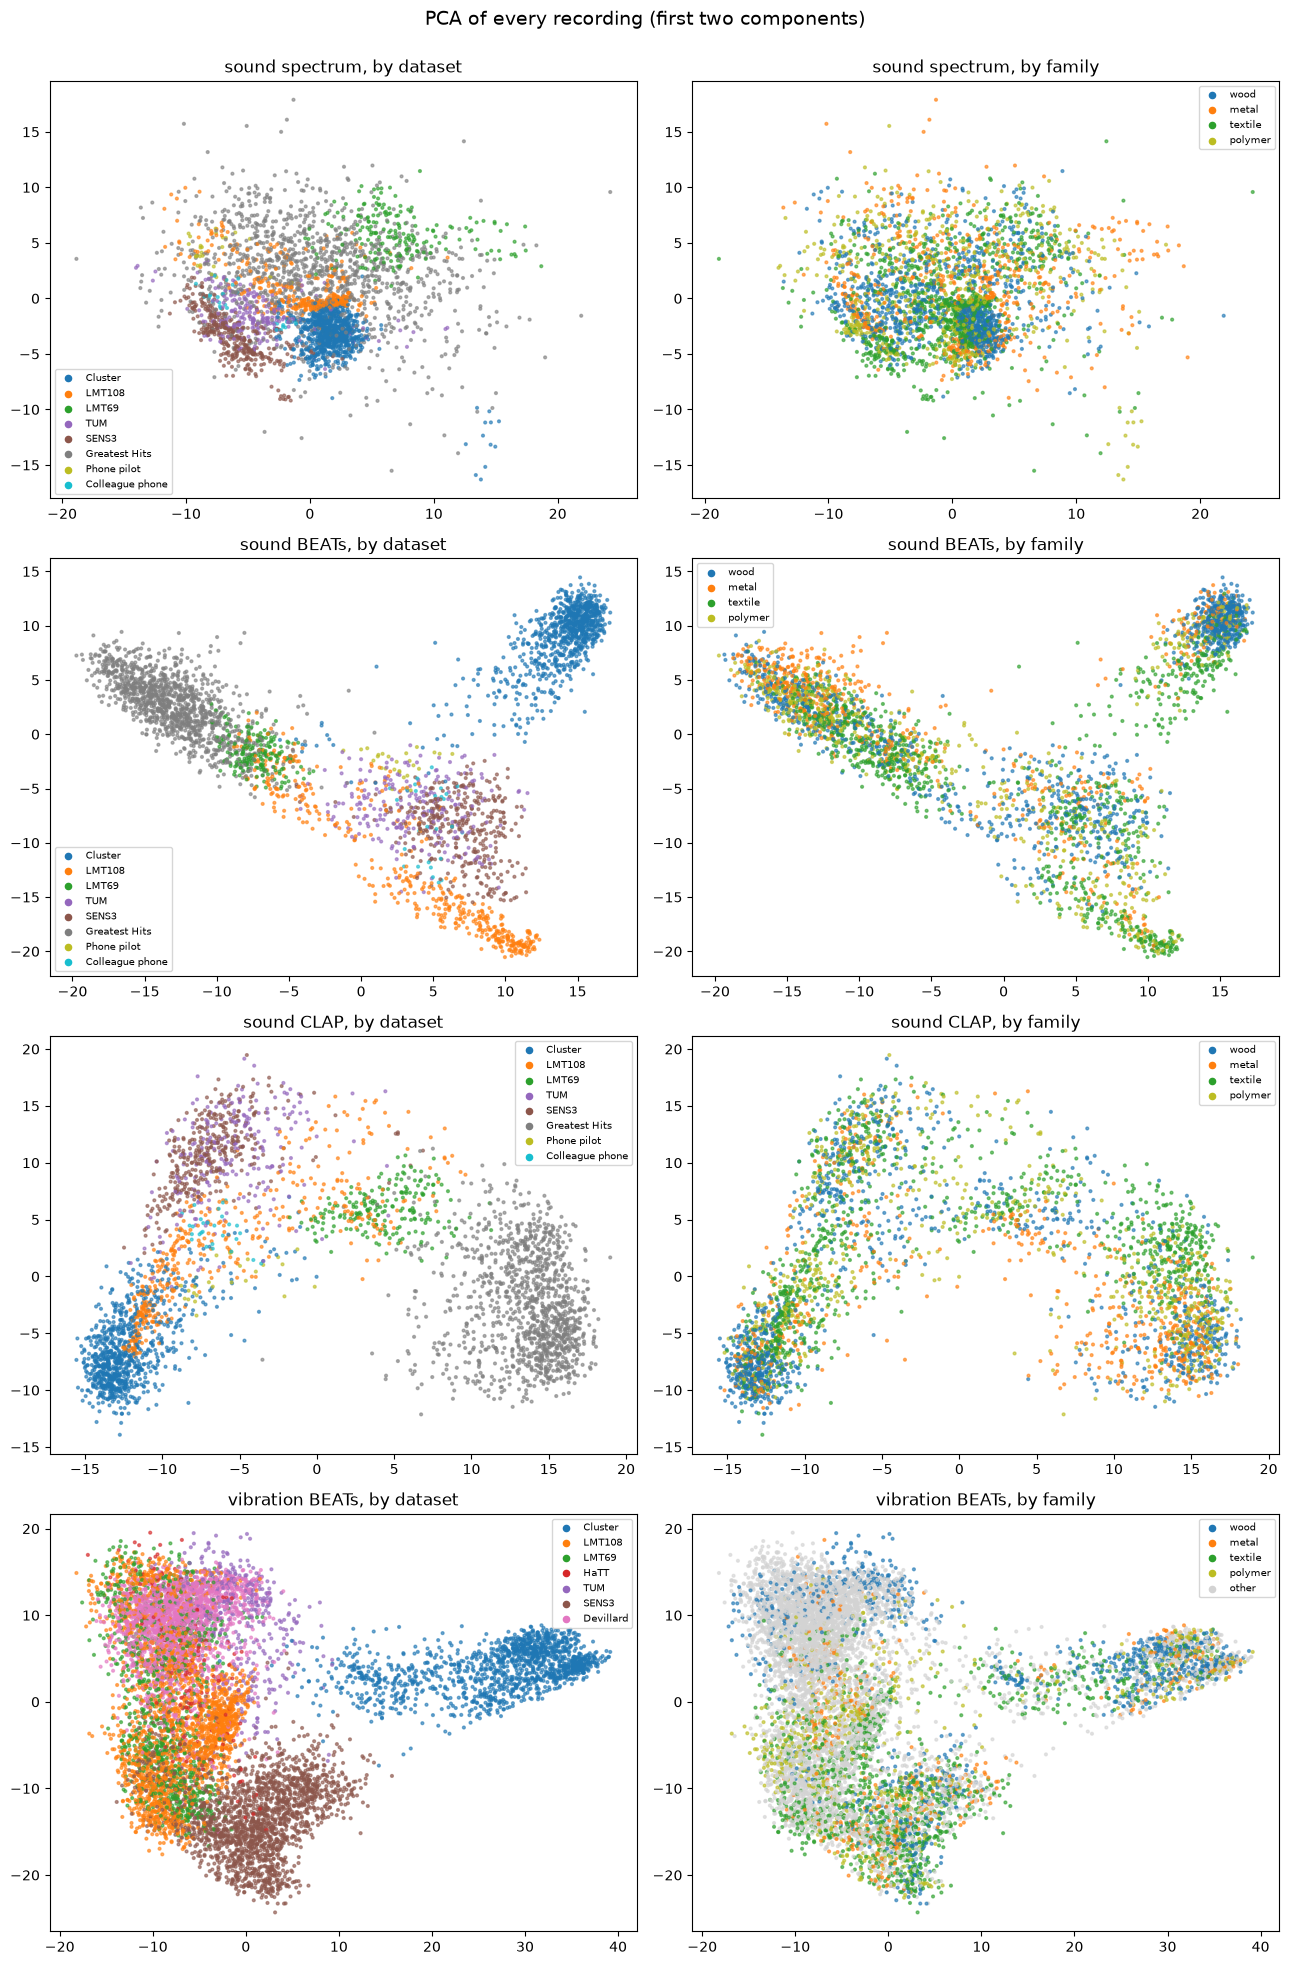

In [7]:
pca_points, explained = {}, {}
for name in REPRESENTATIONS:
    pca = PCA(10).fit(standardized(name))
    pca_points[name] = pca.transform(standardized(name))
    explained[name] = pca.explained_variance_ratio_


def two_maps(points, title, file):
    fig, axes = plt.subplots(len(REPRESENTATIONS), 2, figsize=(13, 5 * len(REPRESENTATIONS)))
    for row, name in enumerate(REPRESENTATIONS):
        xy, labels = points[name], info[name]
        order = np.random.default_rng(0).permutation(len(xy))
        dataset_colors = [DATASET_COLORS[d] for d in labels.dataset.iloc[order]]
        family_colors = [FAMILY_COLORS[f] for f in labels.family.iloc[order]]
        axes[row, 0].scatter(xy[order, 0], xy[order, 1], s=4, alpha=0.6, c=dataset_colors)
        axes[row, 1].scatter(xy[order, 0], xy[order, 1], s=4, alpha=0.6, c=family_colors)
        legend_by(axes[row, 0], [d for d in DATASETS if d in set(labels.dataset)], DATASET_COLORS)
        legend_by(axes[row, 1], [f for f in FAMILY_COLORS if f in set(labels.family)], FAMILY_COLORS)
        axes[row, 0].set_title(f"{name}, by dataset")
        axes[row, 1].set_title(f"{name}, by family")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 0.98))
    plt.savefig(file, dpi=110)


two_maps(pca_points, "PCA of every recording (first two components)", "results/all_datasets_pca.png")
pd.DataFrame({name: np.round(100 * e[:5], 1) for name, e in explained.items()}, index=[f"PC{i}" for i in range(1, 6)])

## t-SNE

PCA only shows the two largest directions. t-SNE (on the first 50 PCA components) keeps the neighbors together, so
small groups show up too. Distances between far groups mean nothing on a t-SNE map.

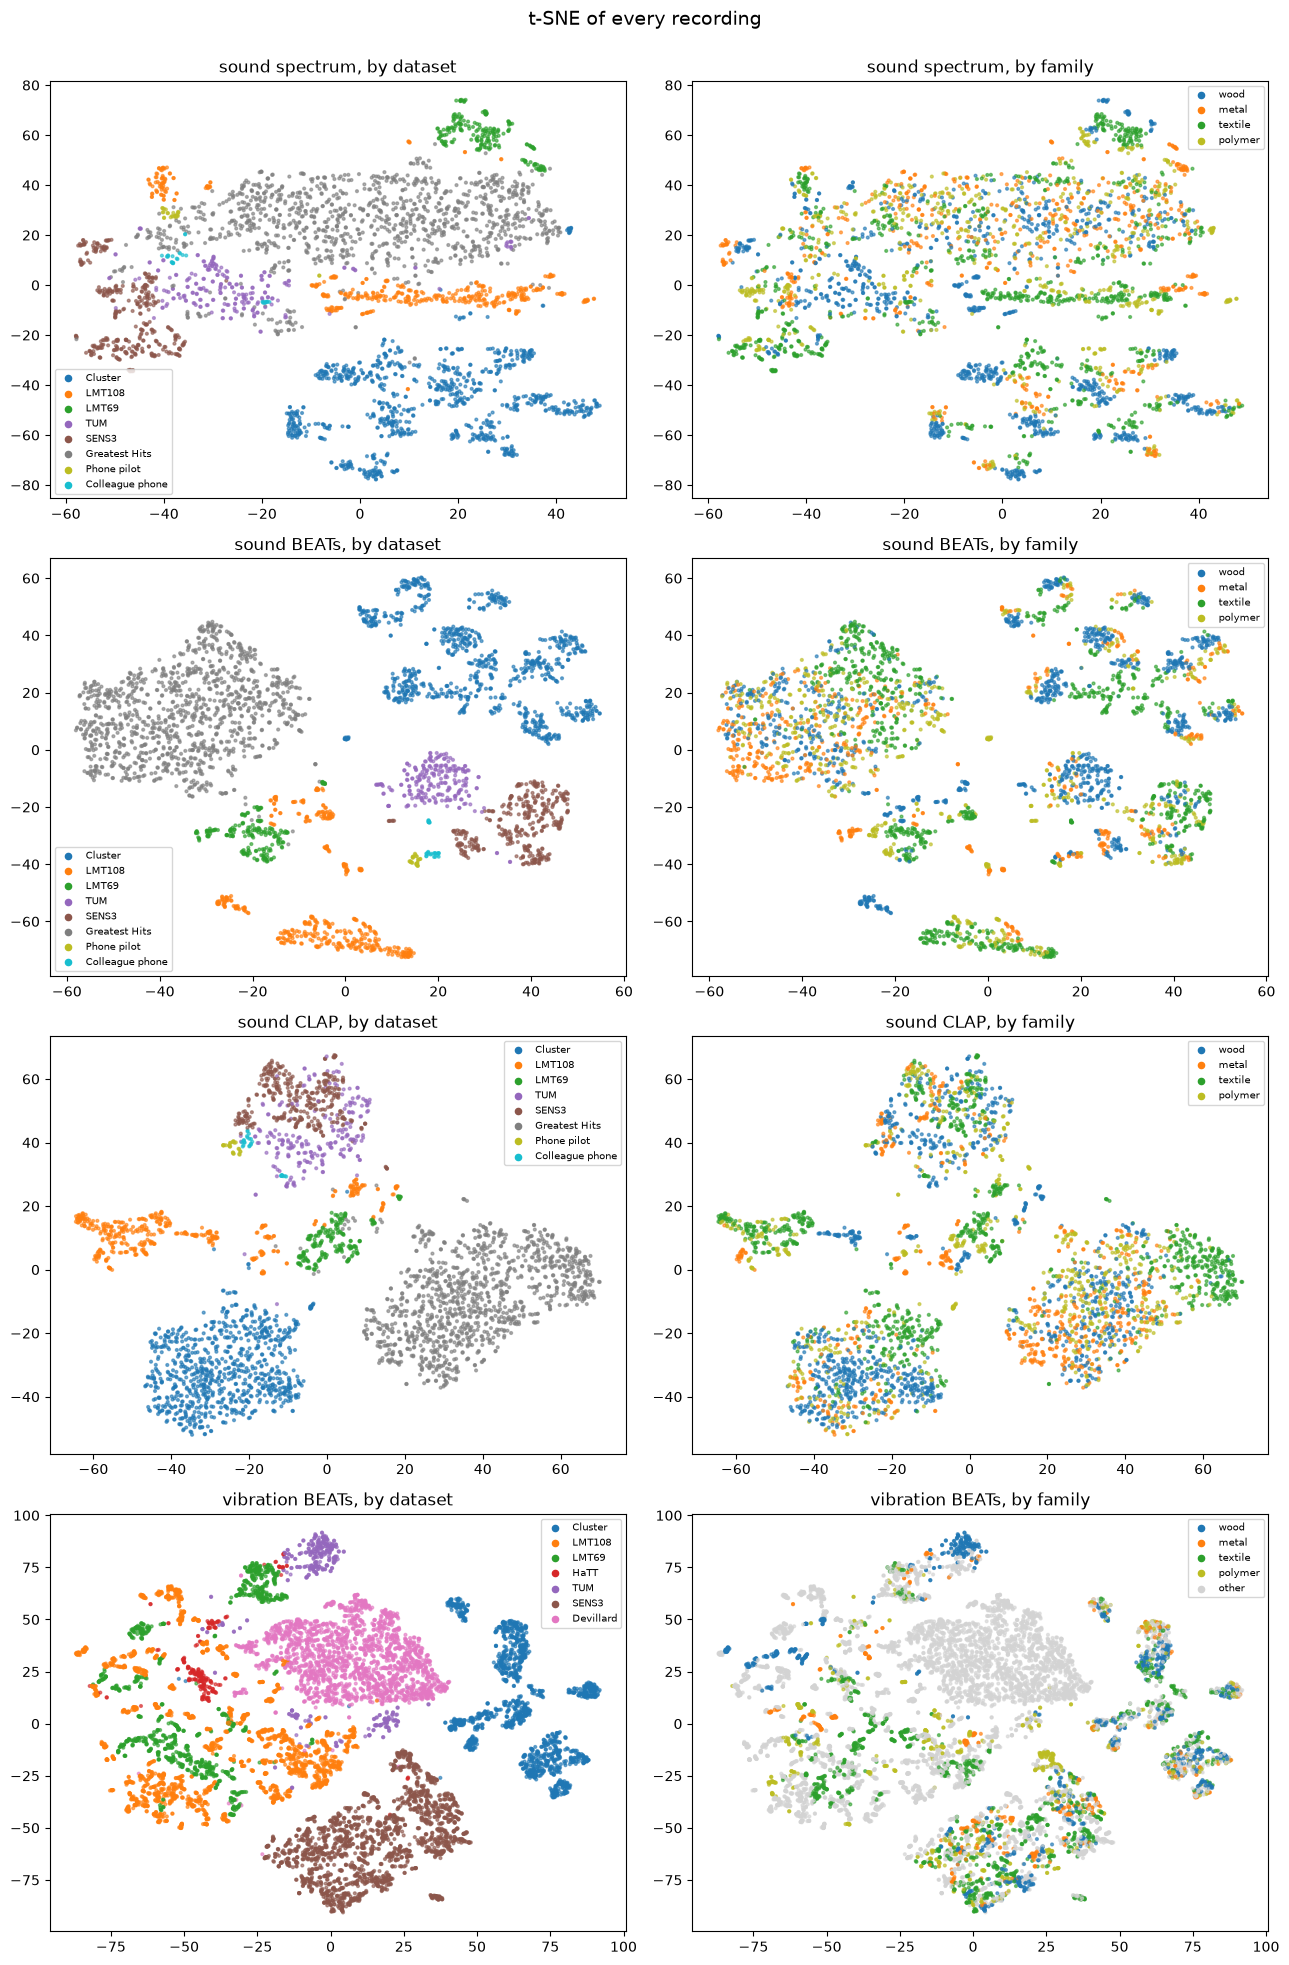

In [8]:
tsne_points = {}
for name in REPRESENTATIONS:
    reduced = PCA(50, random_state=0).fit_transform(standardized(name))
    tsne_points[name] = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(reduced)
two_maps(tsne_points, "t-SNE of every recording", "results/all_datasets_tsne.png")

## How much of the variance does each label explain?

For each representation we split the total variance (sum over all dimensions, after standardizing) into:

- **dataset**: the part explained by the mean of each dataset;
- **family inside the dataset**: what the family adds once the dataset is known (the means of each dataset x family
  pair, minus the dataset means);
- **family alone**: the means of each family, all datasets mixed.

Only recordings of the four families are used here.

,dataset,family inside the dataset,family alone
representation,,,
sound spectrum,0.356,0.059,0.015
sound BEATs,0.325,0.058,0.027
sound CLAP,0.397,0.075,0.035
vibration BEATs,0.355,0.083,0.046


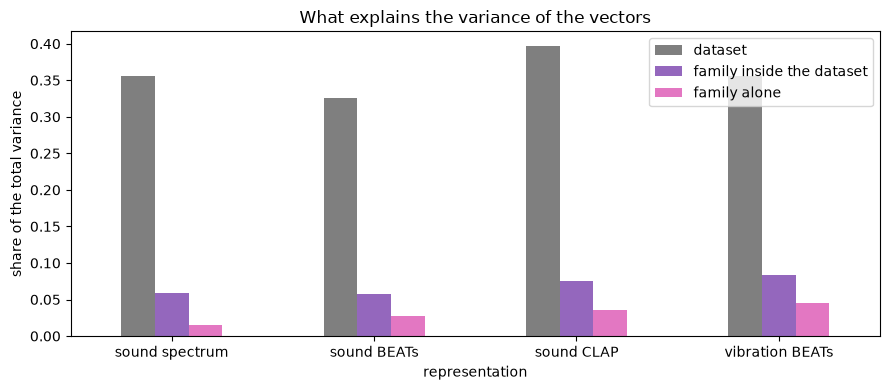

In [9]:
def explained_share(x, groups):
    group_means = pd.DataFrame(x).groupby(np.asarray(groups)).transform("mean").to_numpy()
    return ((group_means - x.mean(axis=0)) ** 2).sum() / ((x - x.mean(axis=0)) ** 2).sum()


rows = []
for name in REPRESENTATIONS:
    known = (info[name].family != "other").to_numpy()
    x = standardized(name)[known]
    labels = info[name][known]
    dataset = explained_share(x, labels.dataset)
    both = explained_share(x, labels.dataset + " " + labels.family)
    rows.append({"representation": name, "dataset": dataset, "family inside the dataset": both - dataset,
                 "family alone": explained_share(x, labels.family)})
variance = pd.DataFrame(rows).set_index("representation")
variance.to_csv("results/all_datasets_variance.csv")

variance.plot.bar(figsize=(9, 4), rot=0, color=["tab:gray", "tab:purple", "tab:pink"])
plt.ylabel("share of the total variance")
plt.title("What explains the variance of the vectors")
plt.tight_layout()
plt.savefig("results/all_datasets_variance.png", dpi=120)
variance.round(3)

## Clustering

We cluster the **surfaces** (one mean vector per surface, so a surface recorded 200 times does not weigh 200 times
more) with k-means, a Gaussian mixture and Ward, on the first 20 PCA components, for 2 to 12 groups. Then we
compare the groups with the datasets and with the families (adjusted Rand index: 1 = same groups, 0 = random).

In [10]:
def per_surface(name):
    labels = info[name]
    key = labels.dataset + " | " + labels.surface
    means = pd.DataFrame(standardized(name)).groupby(key.to_numpy()).mean()
    surface_info = labels.groupby(key.to_numpy()).first().loc[means.index].reset_index(drop=True)
    return means.to_numpy(), surface_info


def three_methods(x, k):
    return {
        "k-means": KMeans(k, n_init=10, random_state=0).fit_predict(x),
        "Gaussian mixture": GaussianMixture(k, covariance_type="diag", n_init=3, random_state=0).fit_predict(x),
        "Ward": AgglomerativeClustering(k).fit_predict(x),
    }


surfaces = {}
rows = []
for name in REPRESENTATIONS:
    x, surface_info = per_surface(name)
    x = PCA(20, random_state=0).fit_transform(x)
    surfaces[name] = (x, surface_info)
    known = (surface_info.family != "other").to_numpy()
    for k in range(2, 13):
        for method, groups in three_methods(x, k).items():
            rows.append({"representation": name, "k": k, "method": method,
                         "dataset": adjusted_rand_score(surface_info.dataset, groups),
                         "family": adjusted_rand_score(surface_info.family[known], groups[known])})
clustering = pd.DataFrame(rows)
clustering.to_csv("results/all_datasets_clustering.csv", index=False)
{name: len(s[1]) for name, s in surfaces.items()}

{'sound spectrum': 811,
 'sound BEATs': 811,
 'sound CLAP': 811,
 'vibration BEATs': 658}

dataset                         family        \
method            Gaussian mixture  Ward k-means Gaussian mixture  Ward   
representation  k                                                         
sound BEATs     4             0.44  0.90    0.47             0.06  0.01   
                7             0.44  0.38    0.38             0.08  0.06   
                8             0.35  0.32    0.27             0.06  0.06   
sound CLAP      4             0.46  0.52    0.50             0.01  0.08   
                7             0.41  0.33    0.31             0.06  0.08   
                8             0.32  0.33    0.31             0.07  0.08   
sound spectrum  4             0.43  0.22    0.12             0.00  0.02   
                7             0.35  0.17    0.14             0.04  0.01   
                8             0.28  0.18    0.12             0.04  0.01   
vibration BEATs 4             0.17  0.33    0.39             0.16  0.18   
                7             0.34  0.52    0.51             0.16  0.21   
                8             0.40  0.52    0.50             0.19  0.21   

                           
method            k-means  
representation  k          
sound BEATs     4    0.08  
                7    0.07  
                8    0.07  
sound CLAP      4    0.10  
                7    0.09  
                8    0.09  
sound spectrum  4    0.02  
                7    0.02  
                8    0.01  
vibration BEATs 4    0.21  
                7    0.22  
                8    0.21

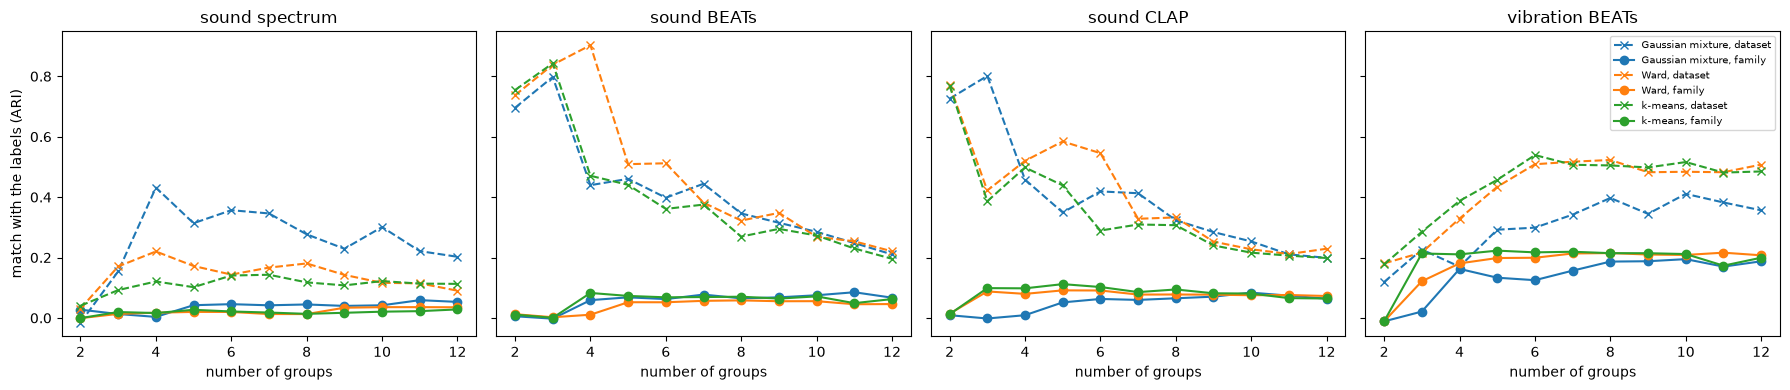

In [11]:
fig, axes = plt.subplots(1, len(REPRESENTATIONS), figsize=(18, 4), sharey=True)
for ax, name in zip(axes, REPRESENTATIONS):
    part = clustering[clustering.representation == name]
    for (method, curve), color in zip(part.groupby("method"), ["tab:blue", "tab:orange", "tab:green"]):
        ax.plot(curve.k, curve.dataset, marker="x", linestyle="--", color=color, label=f"{method}, dataset")
        ax.plot(curve.k, curve.family, marker="o", color=color, label=f"{method}, family")
    ax.set_title(name)
    ax.set_xlabel("number of groups")
axes[0].set_ylabel("match with the labels (ARI)")
axes[-1].legend(fontsize=7)
plt.tight_layout()
plt.savefig("results/all_datasets_clustering.png", dpi=120)
clustering[clustering.k.isin([4, 7, 8])].pivot_table(index=["representation", "k"], columns="method",
                                                     values=["dataset", "family"]).round(2)

What is inside the groups: k-means with as many groups as there are datasets. Rows: dataset and family of the
surfaces. Columns: the groups.

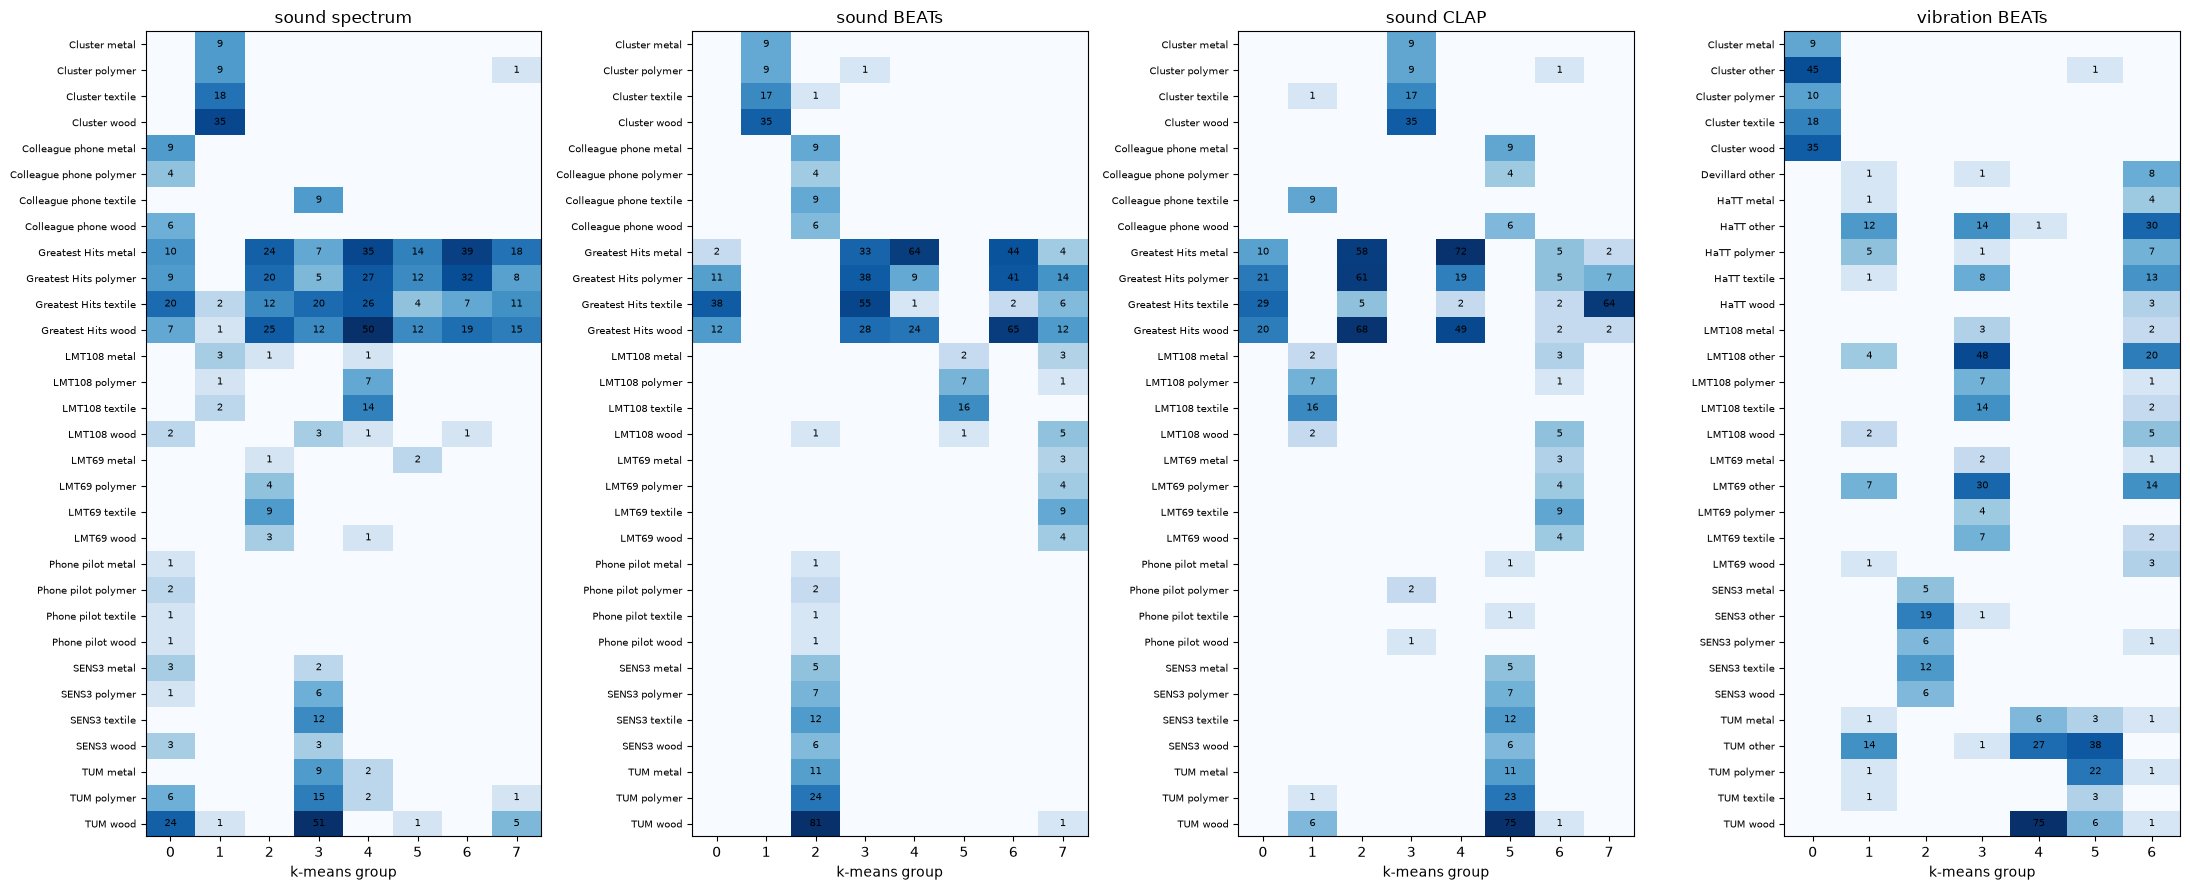

In [12]:
fig, axes = plt.subplots(1, len(REPRESENTATIONS), figsize=(22, 9))
for ax, name in zip(axes, REPRESENTATIONS):
    x, surface_info = surfaces[name]
    k = surface_info.dataset.nunique()
    groups = KMeans(k, n_init=10, random_state=0).fit_predict(x)
    counts = pd.crosstab((surface_info.dataset + " " + surface_info.family).to_numpy(), groups)
    ax.imshow(np.log1p(counts), cmap="Blues", aspect="auto")
    for i in range(counts.shape[0]):
        for j in range(counts.shape[1]):
            if counts.iloc[i, j]:
                ax.text(j, i, counts.iloc[i, j], ha="center", va="center", fontsize=7)
    ax.set_yticks(range(len(counts)), counts.index, fontsize=7)
    ax.set_xticks(range(k), range(k))
    ax.set_xlabel("k-means group")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("results/all_datasets_clustering_groups.png", dpi=110)

## Inside each dataset

The same clustering, but one dataset at a time (k-means, 4 groups, surfaces of the four families only). If the
family is in the signal, it should show up when the dataset is not in the way.

representation,sound BEATs,sound CLAP,sound spectrum,vibration BEATs
dataset,,,,
Cluster,0.55,0.29,0.78,0.37
Colleague phone,0.60,0.50,0.52,NaN
Greatest Hits,0.08,0.15,0.00,NaN
HaTT,NaN,NaN,NaN,0.19
LMT108,0.28,0.30,0.29,0.32
LMT69,0.27,0.16,0.22,0.28
SENS3,0.15,0.11,0.21,0.04
TUM,0.05,0.07,0.06,0.46


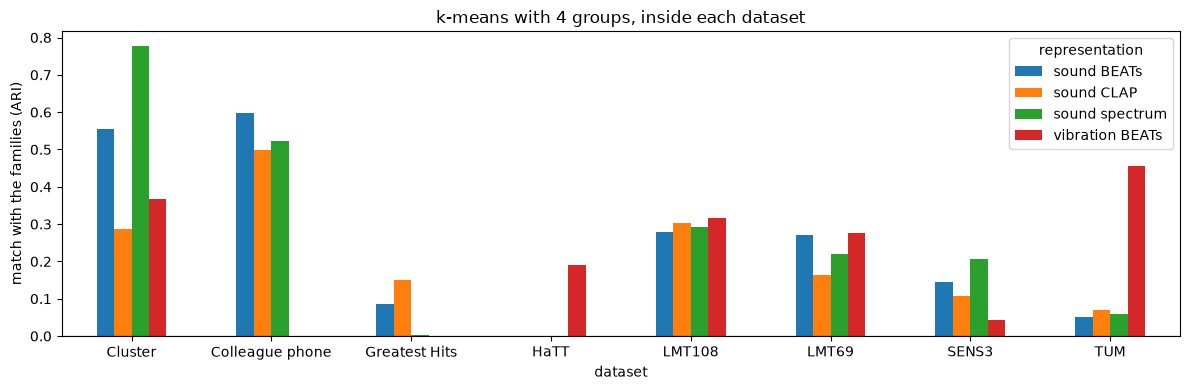

In [13]:
rows = []
for name in REPRESENTATIONS:
    x_all, surface_info = surfaces[name]
    for dataset in surface_info.dataset.unique():
        inside = ((surface_info.dataset == dataset) & (surface_info.family != "other")).to_numpy()
        if inside.sum() < 8 or surface_info.family[inside].nunique() < 2:
            continue
        groups = KMeans(4, n_init=10, random_state=0).fit_predict(x_all[inside])
        rows.append({"representation": name, "dataset": dataset, "surfaces": int(inside.sum()),
                     "families": surface_info.family[inside].nunique(),
                     "family ARI": adjusted_rand_score(surface_info.family[inside], groups)})
inside_scores = pd.DataFrame(rows)
inside_scores.to_csv("results/all_datasets_clustering_inside.csv", index=False)

table = inside_scores.pivot(index="dataset", columns="representation", values="family ARI")
table.plot.bar(figsize=(12, 4), rot=0)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("match with the families (ARI)")
plt.title("k-means with 4 groups, inside each dataset")
plt.tight_layout()
plt.savefig("results/all_datasets_clustering_inside.png", dpi=120)
table.round(2)

## Does removing the mean of each dataset help?

The simplest fix for a setup effect: subtract the mean vector of each dataset (and divide by its spread). This uses
no family label. Then cluster all the surfaces together again, with 4 groups, and compare with the families.

,representation,method,family ARI before,family ARI after,dataset ARI after
0,sound spectrum,k-means,0.02,0.02,-0.01
1,sound spectrum,Gaussian mixture,0.00,0.05,0.09
2,sound spectrum,Ward,0.02,0.02,0.01
3,sound BEATs,k-means,0.08,0.08,-0.01
4,sound BEATs,Gaussian mixture,0.06,0.01,0.07
5,sound BEATs,Ward,0.01,0.07,0.01
6,sound CLAP,k-means,0.10,0.09,-0.06
7,sound CLAP,Gaussian mixture,0.01,0.05,-0.10
8,sound CLAP,Ward,0.08,0.06,-0.20
9,vibration BEATs,k-means,0.21,0.06,0.06


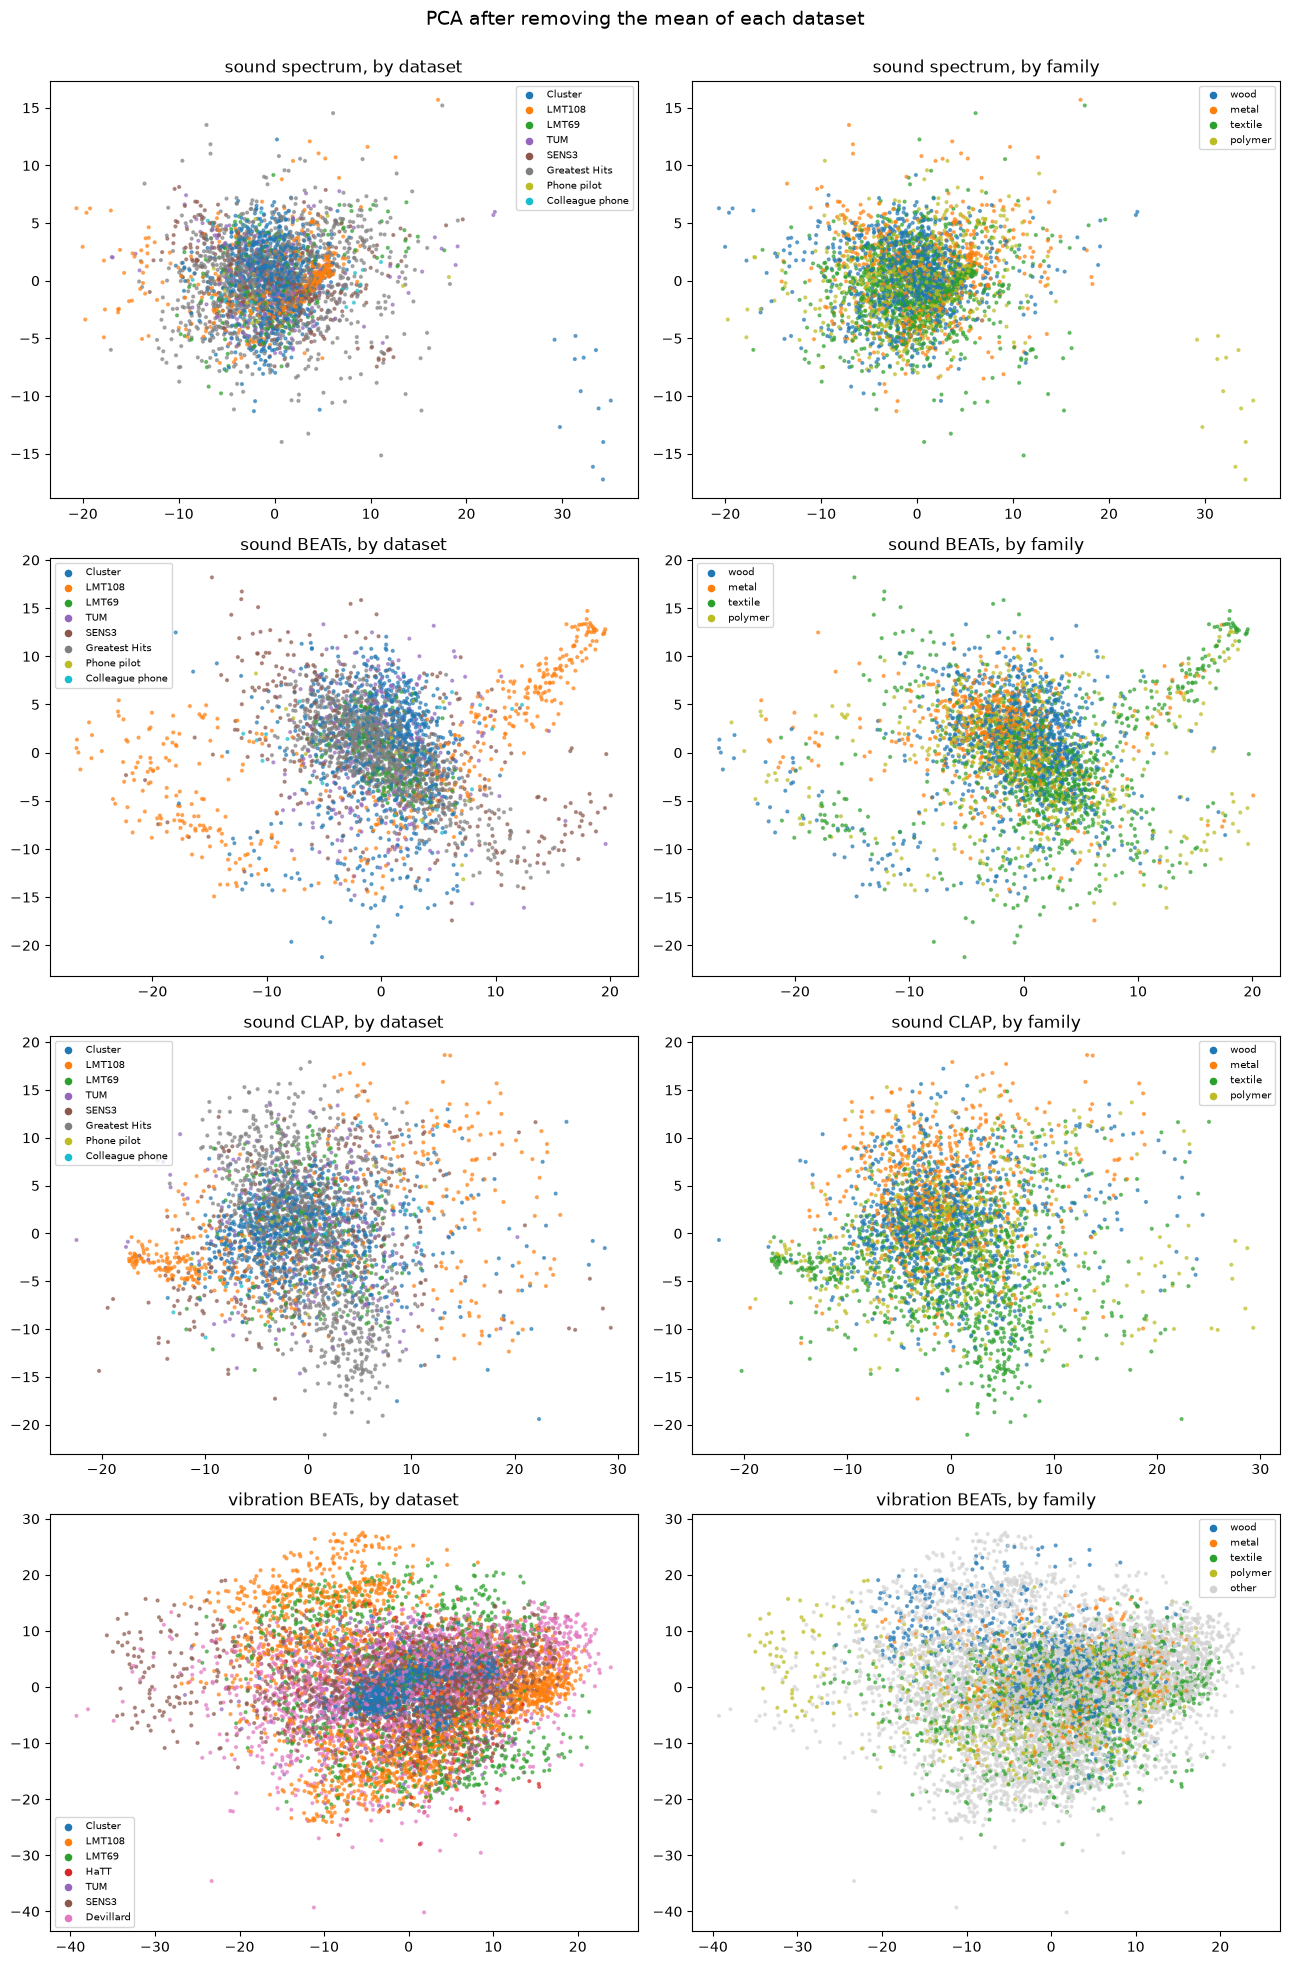

In [14]:
def centered_per_dataset(x, datasets):
    x = x.copy()
    for dataset in np.unique(datasets):
        rows = np.asarray(datasets) == dataset
        x[rows] = StandardScaler().fit_transform(x[rows])
    return x


rows = []
centered_points = {}
for name in REPRESENTATIONS:
    labels = info[name]
    x = centered_per_dataset(standardized(name), labels.dataset.to_numpy())
    centered_points[name] = PCA(2, random_state=0).fit_transform(x)
    key = labels.dataset + " | " + labels.surface
    means = pd.DataFrame(x).groupby(key.to_numpy()).mean()
    surface_info = labels.groupby(key.to_numpy()).first().loc[means.index].reset_index(drop=True)
    reduced = PCA(20, random_state=0).fit_transform(means.to_numpy())
    known = (surface_info.family != "other").to_numpy()
    for method, groups in three_methods(reduced, 4).items():
        before = clustering[(clustering.representation == name) & (clustering.k == 4) & (clustering.method == method)]
        rows.append({"representation": name, "method": method, "family ARI before": before.family.iloc[0],
                     "family ARI after": adjusted_rand_score(surface_info.family[known], groups[known]),
                     "dataset ARI after": adjusted_rand_score(surface_info.dataset, groups)})
centering = pd.DataFrame(rows)
centering.to_csv("results/all_datasets_centering.csv", index=False)
two_maps(centered_points, "PCA after removing the mean of each dataset", "results/all_datasets_pca_centered.png")
centering.round(2)

## Nearest neighbors

For each recording, its closest recording **of another surface** (cosine distance). Is it from the same dataset? Of
the same family? Chance levels: the share of pairs that would match at random.

In [15]:
def nearest_other_surface(name):
    labels = info[name]
    x = standardized(name)
    _, neighbors = NearestNeighbors(n_neighbors=300, metric="cosine").fit(x).kneighbors(x)
    surface = (labels.dataset + " | " + labels.surface).to_numpy()
    nearest = np.full(len(x), -1)
    for i in range(len(x)):
        others = neighbors[i][surface[neighbors[i]] != surface[i]]
        if len(others):
            nearest[i] = others[0]
    return nearest


rows, across = [], []
for name in REPRESENTATIONS:
    labels = info[name]
    nearest = nearest_other_surface(name)
    dataset, family = labels.dataset.to_numpy(), labels.family.to_numpy()
    found = nearest >= 0
    known = found & (family != "other") & (family[nearest] != "other")
    other_dataset = known & (dataset[nearest] != dataset)
    families_known = labels.family[labels.family != "other"]
    rows.append({
        "representation": name,
        "same dataset": (dataset[nearest[found]] == dataset[found]).mean(),
        "same dataset by chance": (labels.dataset.value_counts(normalize=True) ** 2).sum(),
        "same family": (family[nearest[known]] == family[known]).mean(),
        "same family by chance": (families_known.value_counts(normalize=True) ** 2).sum(),
        "neighbors in another dataset": int(other_dataset.sum()),
        "same family, other dataset": (family[nearest[other_dataset]] == family[other_dataset]).mean(),
    })
    for i in np.flatnonzero(other_dataset):
        pair = " / ".join(sorted([dataset[i], dataset[nearest[i]]]))
        across.append({"representation": name, "datasets": pair, "same family": family[i] == family[nearest[i]]})
neighbors_table = pd.DataFrame(rows).set_index("representation")
neighbors_table.to_csv("results/all_datasets_neighbors.csv")
neighbors_table.round(2)

,same dataset,same dataset by chance,same family,same family by chance,neighbors in another dataset,"same family, other dataset"
representation,,,,,,
sound spectrum,0.96,0.23,0.57,0.26,131,0.17
sound BEATs,0.98,0.23,0.64,0.26,71,0.46
sound CLAP,0.96,0.23,0.59,0.26,142,0.36
vibration BEATs,0.95,0.19,0.71,0.28,84,0.74


When the nearest neighbor is in another dataset, which datasets are they? LMT108 and LMT69 come from the same lab
and share textures, so a match between them is not a real change of setup.

In [16]:
across = pd.DataFrame(across)
pairs = across.groupby(["representation", "datasets"])["same family"].agg(neighbors="size", same_family="mean")
pairs[pairs.neighbors >= 3].round(2)

neighbors  same_family
representation  datasets                                             
sound BEATs     Cluster / Greatest Hits                6         0.83
                Cluster / LMT108                       4         0.25
                Greatest Hits / LMT108                 3         0.00
                Greatest Hits / LMT69                 10         0.30
                LMT108 / LMT69                        29         0.76
                SENS3 / TUM                           16         0.12
sound CLAP      Cluster / LMT108                      10         0.20
                Colleague phone / Phone pilot          3         1.00
                Colleague phone / SENS3                6         0.00
                Colleague phone / TUM                  5         0.20
                Greatest Hits / LMT108                 7         0.14
                Greatest Hits / LMT69                  6         0.33
                LMT108 / LMT69                        42         0.76
                LMT108 / SENS3                         3         0.00
                SENS3 / TUM                           54         0.13
sound spectrum  Cluster / Greatest Hits               22         0.09
                Colleague phone / TUM                  6         0.33
                Greatest Hits / LMT108                23         0.17
                Greatest Hits / LMT69                  9         0.11
                Greatest Hits / Phone pilot            9         0.33
                Greatest Hits / SENS3                  3         0.00
                Greatest Hits / TUM                   17         0.24
                LMT108 / LMT69                         4         0.00
                SENS3 / TUM                           32         0.12
vibration BEATs HaTT / TUM                             5         0.20
                LMT108 / LMT69                        75         0.81

## Distances between datasets and families

The mean vector of every dataset x family pair, and the cosine similarity between all pairs. If the families
crossed the setups, the same family of two datasets would be bright; if the setup dominates, each dataset is a
bright block.

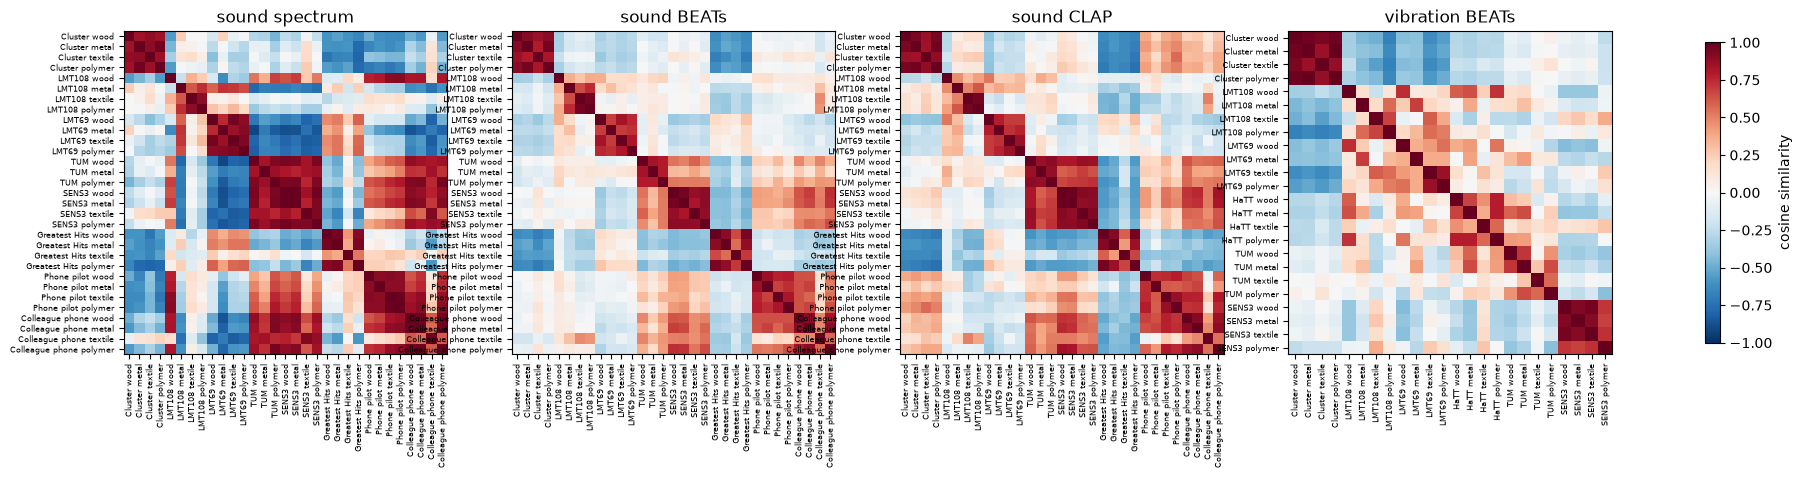

In [17]:
fig, axes = plt.subplots(1, len(REPRESENTATIONS), figsize=(24, 6.5))
for ax, name in zip(axes, REPRESENTATIONS):
    labels = info[name]
    known = (labels.family != "other").to_numpy()
    pair = (labels.dataset + " " + labels.family)[known].to_numpy()
    means = pd.DataFrame(standardized(name)[known]).groupby(pair).mean()
    order = sorted(means.index, key=lambda p: (DATASETS.index(p.rsplit(" ", 1)[0]), FAMILIES.index(p.rsplit(" ", 1)[1])))
    means = means.loc[order].to_numpy()
    unit = means / np.linalg.norm(means, axis=1, keepdims=True)
    picture = ax.imshow(unit @ unit.T, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(order)), order, rotation=90, fontsize=6)
    ax.set_yticks(range(len(order)), order, fontsize=6)
    ax.set_title(name)
plt.colorbar(picture, ax=axes, shrink=0.6, label="cosine similarity")
plt.savefig("results/all_datasets_similarity.png", dpi=110, bbox_inches="tight")

The same means as a tree (Ward on the cosine-normalized means): which pairs join first?

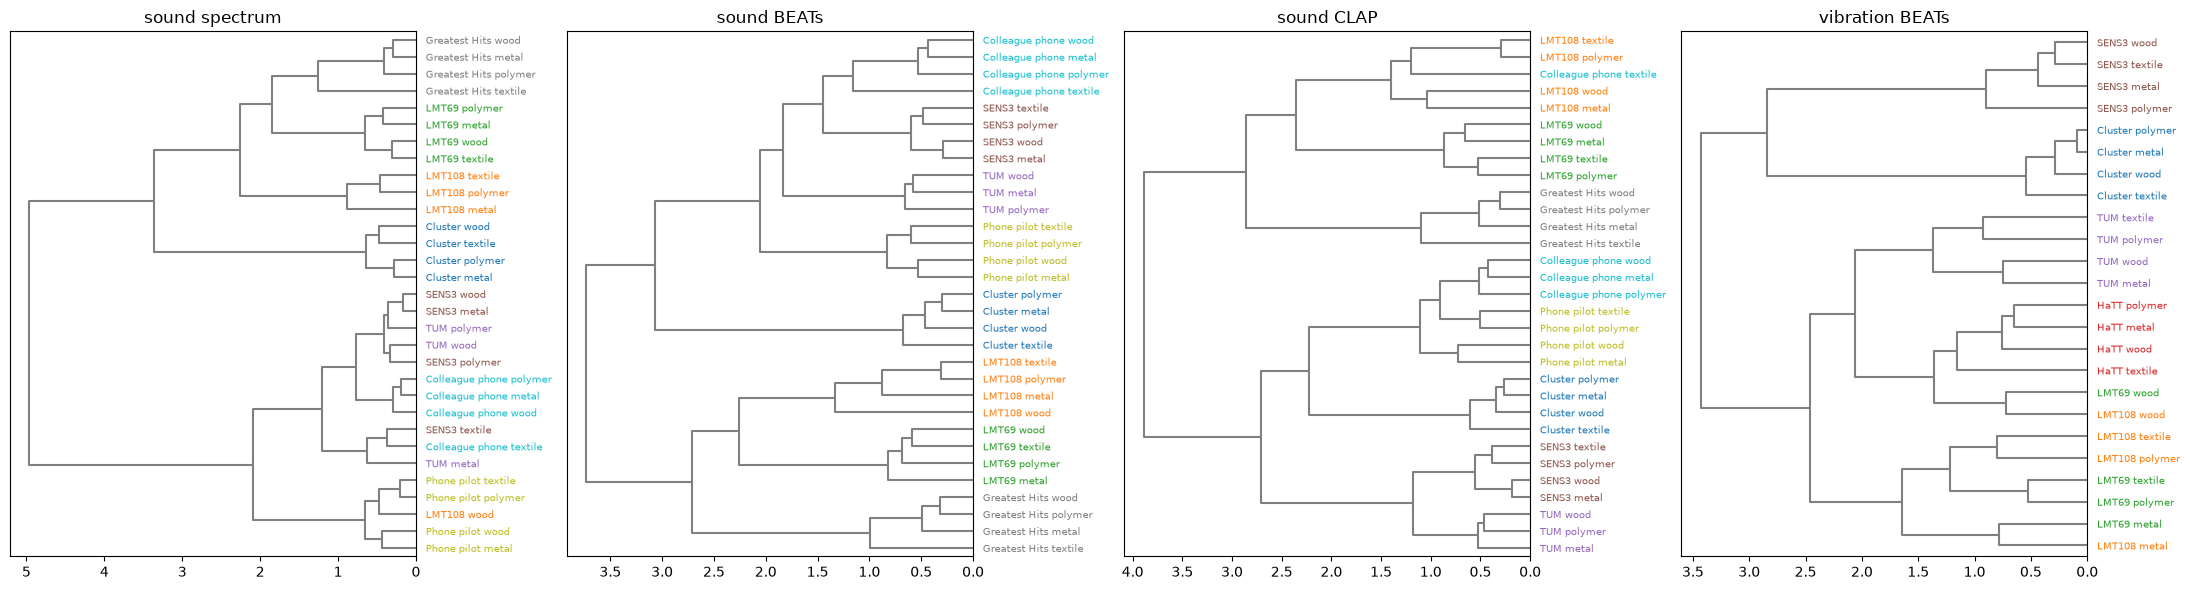

In [18]:
fig, axes = plt.subplots(1, len(REPRESENTATIONS), figsize=(22, 6))
for ax, name in zip(axes, REPRESENTATIONS):
    labels = info[name]
    known = (labels.family != "other").to_numpy()
    pair = (labels.dataset + " " + labels.family)[known].to_numpy()
    means = pd.DataFrame(standardized(name)[known]).groupby(pair).mean()
    unit = means.to_numpy() / np.linalg.norm(means.to_numpy(), axis=1, keepdims=True)
    tree = dendrogram(linkage(unit, "ward"), labels=means.index.tolist(), orientation="left", ax=ax,
                      color_threshold=0, above_threshold_color="gray")
    for text in ax.get_yticklabels():
        dataset = text.get_text().rsplit(" ", 1)[0]
        text.set_color(DATASET_COLORS[dataset])
        text.set_fontsize(7)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("results/all_datasets_tree.png", dpi=110)

## What we see

- **Every map is a map of the datasets.** On the PCA and on the t-SNE, each dataset is its own island, with every
  representation, with and without a pretrained model. The families are mixed inside each island.
- **Variance**: the dataset explains 33-40 % of the variance of the vectors, the family 2-5 % (all datasets
  mixed), and 6-8 % once the dataset is known.
- **Nearest neighbor** (from another surface): it is in the same dataset 95-98 % of the time (19-23 % by chance). It
  has the same family 57-71 % of the time (26-28 % by chance), but almost always inside the same dataset. The rare
  neighbors from another dataset have the same family 17-46 % of the time with the sound. With the vibration it is
  74 %, but 75 of these 84 pairs are LMT108 / LMT69: the same lab and the same textures.
- **Clustering all the surfaces** finds the datasets (ARI up to 0.90), not the families (0.00-0.10 with the
  sound, about 0.2 with the vibration, partly because the datasets do not have the same mix of families: TUM is
  mostly wood).
- **Inside one dataset**, the families show up in some cases: Cluster (0.78 with the plain sound spectrum, 0.55
  with BEATs), TUM with the vibration (0.46), LMT108 and LMT69 (about 0.3). Not in SENS3 (bare finger) or in
  Greatest Hits (drumstick in videos).
- **Removing the mean of each dataset** does not bring the families out: the family ARI of all the surfaces stays
  at 0.10 or less.
- On the similarity matrices each dataset is a bright block. With the plain spectrum, SENS3, TUM and the two phones
  look alike; the pretrained models separate them more.

This is the picture behind the rest of the project: the change of setup moves a recording much more than the change
of material. A classifier trained on some setups has to work across these gaps (`new_setup.ipynb`), and a few labels
of the new setup are what brings the families back (`few_labels.ipynb`).